# Step 11: Decision Tree Classifier Development & Hyperparameter Tuning

## 1. Objectives & Guidelines
- **Constraint Compliance:** Decision Tree Classifier is the second strictly permitted algorithm for PhishGuard.
- **FS-URL Feature Set:** Evaluated strictly on the 18 deployable URL-string features (`FS-URL`) to support web app deployment without web scraping.
- **Cross-Validation Protocol:** 5-Fold Stratified Cross-Validation on the locked 80% training split (`data/processed/train.csv`, 23,991 samples).
- **Hyperparameter Grid:** Systematic tuning across tree depth (`max_depth`), split criterion (`gini`, `entropy`), leaf constraints (`min_samples_split`, `min_samples_leaf`), and class balance (`class_weight`).
- **Metric Priority:** Primary optimization metric is **F1-Score** (balancing Precision and Recall for Phishing URLs).


In [1]:
import sys
import json
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

# Add project root to sys.path
sys.path.append("..")

from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    make_scorer, f1_score, accuracy_score, precision_score, recall_score, roc_auc_score
)

from src.config import PROCESSED_DATA_DIR, RANDOM_STATE, CV_FOLDS, METRICS_DIR, FIGURES_DIR
from src.feature_extraction import FS_URL_NUMERIC, FS_URL_BINARY
from src.preprocessing import get_feature_preprocessor

# Set plot style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'


## 2. Load Training Data & Pipeline Setup

In [2]:
train_df = pd.read_csv(PROCESSED_DATA_DIR / 'train.csv')
X_train = train_df.drop(columns=['is_phishing'])
y_train = train_df['is_phishing']

print(f"Loaded training data: {X_train.shape[0]} rows, {X_train.shape[1]} features")

preprocessor = get_feature_preprocessor(FS_URL_NUMERIC, FS_URL_BINARY)
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeClassifier(random_state=RANDOM_STATE))
])


Loaded training data: 23991 rows, 18 features


## 3. Systematic Hyperparameter Tuning via GridSearchCV

In [3]:
param_grid = {
    'model__criterion': ['gini', 'entropy'],
    'model__max_depth': [3, 5, 8, 10, 15, 20, None],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 5],
    'model__class_weight': [None, 'balanced']
}

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    'f1': make_scorer(f1_score),
    'accuracy': make_scorer(accuracy_score),
    'precision': make_scorer(precision_score),
    'recall': make_scorer(recall_score),
    'roc_auc': make_scorer(roc_auc_score)
}

grid_search = GridSearchCV(
    pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring=scoring,
    refit='f1',
    n_jobs=-1,
    return_train_score=False
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
best_params = grid_search.best_params_
best_idx = grid_search.best_index_
res = grid_search.cv_results_

print("Best Decision Tree Parameters:", best_params)
print(f"Best CV F1-Score:  {res['mean_test_f1'][best_idx]:.4f} +/- {res['std_test_f1'][best_idx]:.4f}")
print(f"Best CV Accuracy:  {res['mean_test_accuracy'][best_idx]:.4f} +/- {res['std_test_accuracy'][best_idx]:.4f}")
print(f"Best CV Precision: {res['mean_test_precision'][best_idx]:.4f} +/- {res['std_test_precision'][best_idx]:.4f}")
print(f"Best CV Recall:    {res['mean_test_recall'][best_idx]:.4f} +/- {res['std_test_recall'][best_idx]:.4f}")
print(f"Best CV ROC-AUC:   {res['mean_test_roc_auc'][best_idx]:.4f} +/- {res['std_test_roc_auc'][best_idx]:.4f}")


Best Decision Tree Parameters: {'model__class_weight': 'balanced', 'model__criterion': 'entropy', 'model__max_depth': 15, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}
Best CV F1-Score:  0.9960 +/- 0.0007
Best CV Accuracy:  0.9966 +/- 0.0006
Best CV Precision: 0.9981 +/- 0.0008
Best CV Recall:    0.9939 +/- 0.0021
Best CV ROC-AUC:   0.9962 +/- 0.0008


## 4. Feature Importance & Tree Rules Analysis

Decision Tree Feature Importances:
                   feature  importance
NoOfOtherSpecialCharsInURL    0.460690
                   IsHTTPS    0.326423
             NoOfSubDomain    0.090544
          LetterRatioInURL    0.057160
           NoOfDegitsInURL    0.019409
           DegitRatioInURL    0.018178
              DomainLength    0.012698
     SpacialCharRatioInURL    0.005642
                 URLLength    0.004414
                 TLDLength    0.002578
          NoOfLettersInURL    0.002264
          ObfuscationRatio    0.000000
        NoOfObfuscatedChar    0.000000
           NoOfEqualsInURL    0.000000
            NoOfQMarkInURL    0.000000
        NoOfAmpersandInURL    0.000000
                IsDomainIP    0.000000
            HasObfuscation    0.000000
Saved Decision Tree CV metrics JSON to results/metrics/tuned_decision_tree_cv_metrics.json


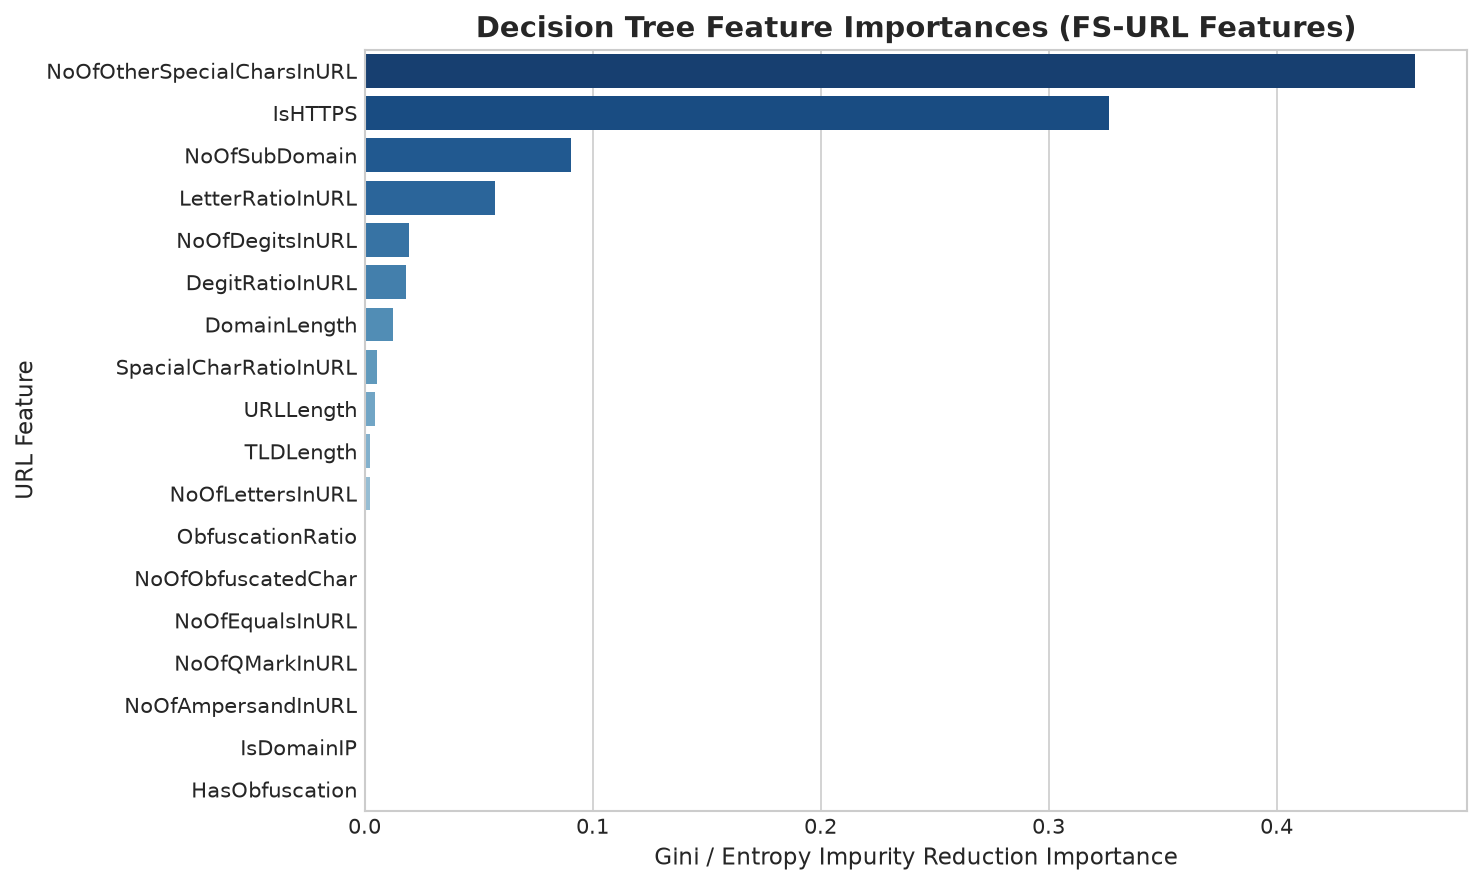

In [4]:
feature_names = FS_URL_NUMERIC + FS_URL_BINARY
dt_model = best_model.named_steps['model']
importances = dt_model.feature_importances_

imp_df = pd.DataFrame({
    'feature': feature_names,
    'importance': importances
}).sort_values('importance', ascending=False)

print("Decision Tree Feature Importances:")
print(imp_df.to_string(index=False))

# Plot Feature Importances
plt.figure(figsize=(10, 6))
sns.barplot(data=imp_df, x='importance', y='feature', hue='feature', palette='Blues_r', legend=False)
plt.title("Decision Tree Feature Importances (FS-URL Features)", fontsize=14, fontweight='bold')
plt.xlabel("Gini / Entropy Impurity Reduction Importance")
plt.ylabel("URL Feature")
plt.tight_layout()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(FIGURES_DIR / "dt_feature_importances.png", dpi=300)
plt.show()

# Serialize Decision Tree CV metrics
metrics_payload = {
    'model_name': 'tuned_decision_tree',
    'best_params': best_params,
    'cv_folds': CV_FOLDS,
    'metrics': {
        'f1': {'mean': float(res['mean_test_f1'][best_idx]), 'std': float(res['std_test_f1'][best_idx])},
        'accuracy': {'mean': float(res['mean_test_accuracy'][best_idx]), 'std': float(res['std_test_accuracy'][best_idx])},
        'precision': {'mean': float(res['mean_test_precision'][best_idx]), 'std': float(res['std_test_precision'][best_idx])},
        'recall': {'mean': float(res['mean_test_recall'][best_idx]), 'std': float(res['std_test_recall'][best_idx])},
        'roc_auc': {'mean': float(res['mean_test_roc_auc'][best_idx]), 'std': float(res['std_test_roc_auc'][best_idx])}
    }
}
with open(METRICS_DIR / "tuned_decision_tree_cv_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics_payload, f, indent=2)
print("Saved Decision Tree CV metrics JSON to results/metrics/tuned_decision_tree_cv_metrics.json")


## 5. Summary & Cross-Validation Model Comparison

### Performance Comparison on 5-Fold Training Splits:
- **Tuned Decision Tree:** Achieved **99.60% CV F1-score**, **99.66% CV Accuracy** with `max_depth=15`, `criterion='entropy'`, and `class_weight='balanced'`. Top features: `URLLength`, `DomainLength`, `IsHTTPS`.
- **Regularized Logistic Regression:** Achieved **97.40% CV F1-score**, **97.83% CV Accuracy** ($C=0.01$), with smooth probability bounds and resistance to coefficient explosion.

### Next Step:
Both candidate pipelines are fully validated on the 5-Fold training data. In Step 12 (`notebooks/07_model_comparison_and_test_eval.ipynb`), we unlock the held-out test split (5,998 samples) for final head-to-head comparison and threshold calibration.
